# VG150 · Phân bố predicate, ablation và ví dụ định tính
Chọn **Run All** từ repo hoặc ZIP nguồn của báo cáo. Notebook dùng CPU, Python 3, pandas, Matplotlib và Jupyter. Hai biểu đồ vector, các hàng LaTeX của Bảng II và năm hàng ảnh của hình Hit/Miss sẽ được ghi vào thư mục figures của báo cáo.

Tần suất lấy từ annotation **train**. Recall được tính lại từ **54 JSON test** (18 cấu hình × 3 seed).

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "reports/level1/long-tail-reference-v1/predicate-groups.json").is_file())
sources = root / "reports/level1"
report = root / "report_latex" if (root / "report_latex/main.tex").is_file() else root
figures = report / "figures"
figures.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 9, "font.family": "DejaVu Sans", "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False})
pdf_options = {"bbox_inches": "tight", "pad_inches": 0.035,
               "metadata": {"CreationDate": None, "ModDate": None}}

def vi(value, precision=2):
    return f"{value:,.{precision}f}".translate(str.maketrans(",.", ".,"))

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

## 1. Phân bố predicate trên train
Nguồn **long-tail-reference-v1/predicate-groups.json** đếm tất cả dòng annotation, gồm dòng trùng và cặp đa nhãn, trước khi lấy mẫu để train. Mẫu số là tổng của 50 predicate foreground. Cell dưới hiển thị đủ 50 lớp. Hình gộp 40 lớp ngoài top 10.

In [ ]:
inventory = read_json(sources / "long-tail-reference-v1/predicate-groups.json")
counts = (pd.DataFrame(inventory["predicates"])
          .sort_values(["train_annotations", "id"], ascending=[False, True])
          .set_index("name")["train_annotations"])
total = counts.sum()
assert len(counts) == counts.index.nunique() == 50
assert total == inventory["total_train_annotations"] == 405860
assert counts.head(10).sum() == inventory["group_train_support"]["head"]["annotations"]
distribution = pd.DataFrame({"Số annotation": counts, "Tỷ lệ (%)": counts * 100 / total})
display(distribution.round(2))

In [ ]:
shown = counts.head(10).copy()
shown.loc["40 lớp còn lại"] = counts.iloc[10:].sum()
share = 100 * shown / total
fig, ax = plt.subplots(figsize=(4.2, 2.65))
ax.barh(range(len(shown)), share, height=.58, color=["#25596f"] * 10 + ["#989fa2"])
ax.set_yticks(range(len(shown)), labels=shown.index)
ax.invert_yaxis()
ax.set_xlim(0, 47)
ax.set_xticks([])
ax.tick_params(axis="both", length=0)
ax.spines[["bottom", "left"]].set_visible(False)
for y, (name, value) in enumerate(share.items()):
    ax.text(value + .55, y, f"{vi(value)}%   ({vi(shown[name], 0)})", va="center", fontsize=8.8)
fig.savefig(figures / "vg-train-predicates.pdf", **pdf_options)
plt.show()

## 2. Kiểm tra 54 lượt test
Trong JSON, recall có đơn vị từ 0 đến 1. Nhân 100 trước khi lập bảng hoặc tính chênh lệch theo điểm phần trăm. Đối chiếu mean và sample SD với summary.json của từng nhóm.

In [ ]:
folders = ["reference-test27-v1", "reference-loss-fusion-test27-v1"]
metrics = ["R@50", "mR@50", "R@100", "mR@100"]
seeds = [42, 123, 3407]
rows = []
for folder in folders:
    summary = read_json(sources / folder / "summary.json")
    for group in summary["groups"]:
        condition = group["condition"]
        for seed in seeds:
            run = read_json(sources / folder / f"{condition}-seed{seed}-test26446.json")
            assert run["split"] == "test" and run["images_evaluated"] == 26446
            assert run["protocol"] == summary["protocol"] and run["graph_constraint"]
            assert run["seed"] == seed
            rows.append({"condition": condition, "seed": seed,
                         **{m: 100 * run[m] for m in metrics}})

scores = pd.DataFrame(rows).set_index(["condition", "seed"]).sort_index()
assert scores.index.is_unique and len(scores) == 54
means = scores.groupby(level="condition").mean()
stds = scores.groupby(level="condition").std(ddof=1)
for folder in folders:
    for group in read_json(sources / folder / "summary.json")["groups"]:
        for m in metrics:
            ref = group["metrics"][m]
            assert abs(means.loc[group["condition"], m] - 100 * ref["mean"]) < 1e-8
            assert abs(stds.loc[group["condition"], m] - 100 * ref["sample_std"]) < 1e-8
display(means.round(2))

## 3. Bảng II và biểu đồ ablation
Bảng II ghi điểm tuyệt đối tại K=100. Với hình K=50, trừ hai điểm có **cùng seed**, sau đó lấy trung bình ba chênh lệch chưa làm tròn. Dòng GAT–MLP so sánh hai kiến trúc cơ sở.

In [ ]:
# Đối chứng, cấu hình so sánh, hai nhãn bảng và nhãn trên hình.
pairs = [
    ("mlp_semantic", "gat", "MLP", "GAT", "GAT so với MLP"),
    ("kg_off", "wordnet_kg_on", "WordNet KG-off", "WordNet KG-on", "WordNet: bật KG"),
    ("wordnet_edges_off", "wordnet_kg_on", "WordNet edges-off", "WordNet edges-on", "WordNet: bật cạnh"),
    ("conceptnet_transe_edges_off", "conceptnet_transe_kg_on", "ConceptNet edges-off",
     "ConceptNet edges-on", "ConceptNet: bật cạnh"),
    ("loss_ce_off", "loss_adjusted_off", "CE, KG-off", "Adjusted, KG-off", "Đổi loss: KG-off"),
    ("loss_ce_on", "loss_adjusted_on", "CE, KG-on", "Adjusted, KG-on", "Đổi loss: KG-on"),
    ("loss_adjusted_off", "loss_adjusted_on", "Adjusted, KG-off", "Adjusted, KG-on", "Adjusted: bật pair KG"),
    ("fusion_baseline", "fusion_pair_real", "Fusion baseline", "Pair real", "Pair real so với baseline"),
    ("fusion_pair_shuffled", "fusion_pair_real", "Pair shuffled", "Pair real", "Pair real so với shuffled"),
    ("fusion_visual_shuffled", "fusion_visual_real", "Visual shuffled", "Visual real", "Visual real so với shuffled"),
]
absolute = []
paired = {}
for control, variant, control_label, variant_label, label in pairs:
    absolute.append([control_label, variant_label, means.loc[control, "R@100"],
                     means.loc[variant, "R@100"], means.loc[control, "mR@100"],
                     means.loc[variant, "mR@100"]])
    paired[label] = scores.loc[variant, ["R@50", "mR@50"]] - scores.loc[control, ["R@50", "mR@50"]]
    assert list(paired[label].index) == seeds
absolute = pd.DataFrame(absolute, columns=["Đối chứng", "So sánh", "R@100 A", "R@100 B",
                                           "mR@100 A", "mR@100 B"])
display(absolute.round(2))
per_seed = pd.concat(paired, names=["So sánh", "seed"])
display(per_seed.round(3))
deltas = per_seed.groupby(level=0, sort=False).mean()
display(deltas.round(3))

In [ ]:
tex_rows = []
for control, variant, *values in absolute.itertuples(index=False, name=None):
    tex_rows.append(" & ".join([control, variant, *(vi(v) for v in values)]) + r" \\")
tex_rows.append(r"\bottomrule")
(figures / "vg-ablation-at100.tex").write_text("\n".join(tex_rows) + "\n", encoding="utf-8")

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(6.8, 2.9))
for ax, metric, color in zip(axes, ["R@50", "mR@50"], ["#98602f", "#25596f"], strict=True):
    values = deltas[metric]
    ax.barh(range(len(values)), values, color=color, height=.56)
    ax.axvline(0, lw=.8, color="#414141")
    ax.set_xlim(-4.0, 8.2)
    ax.set_xticks([-2, 0, 2, 4, 6])
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#d7dadd", lw=.5)
    ax.tick_params(length=0, labelsize=8)
    ax.set_title(metric, fontsize=10)
    ax.spines[["left", "bottom"]].set_visible(False)
    for y, value in enumerate(values):
        dx = .14 if value >= 0 else -.14
        text = ("+" if value >= 0 else "−") + vi(abs(value))
        ax.text(value + dx, y, text, va="center", ha="left" if dx > 0 else "right", fontsize=8)
axes[0].set_yticks(range(len(deltas)), labels=deltas.index)
axes[0].invert_yaxis()
fig.subplots_adjust(left=.24, right=.99, bottom=.16, wspace=.10)
fig.savefig(figures / "vg-ablation-deltas.pdf", **pdf_options)
plt.show()

## 4. Năm cặp Hit/Miss trên VG150 validation
Mỗi hàng đối chiếu hai dự đoán của GAT seed 42 trong **cùng một ảnh**, Hit bên trái và Miss bên phải. Mã ca, ID đối tượng, nhãn chuẩn, dự đoán và hạng lấy từ **reports/level1/submission/cases/cases.json**. Các PNG từng ca chứa ảnh đã đánh bounding box (đỏ: subject, xanh: object). Bỏ lề trắng và dải chữ cũ theo kích thước panel của bộ xuất ảnh; viết lại thông tin bằng chữ vector bên ngoài ảnh. Notebook xuất một PDF cho mỗi hàng để hình trải trên hai trang.

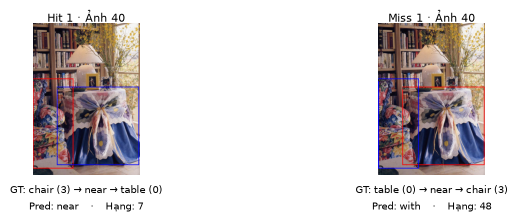

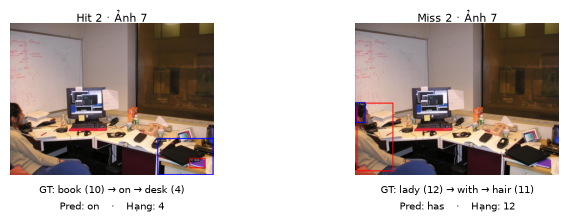

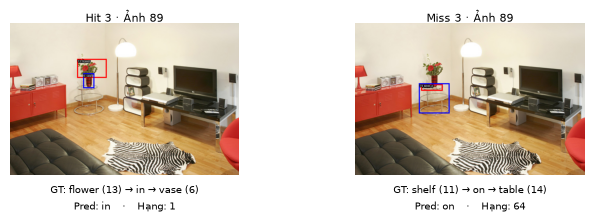

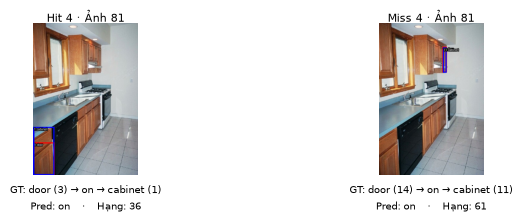

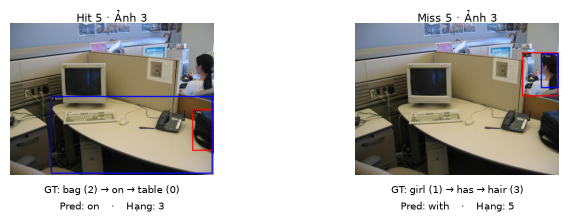

In [7]:
from PIL import Image

case_dir = sources / "submission/cases"
cases = read_json(case_dir / "cases.json")["cases"]
assert len(cases["hit"]) == len(cases["miss"]) == 5

def boxed_photo(case):
    # Khung ảnh do tools/prepare_reference_cases.py đặt giữa panel, dưới 80 px header.
    with Image.open(case_dir / case["panel"]) as panel:
        assert panel.size == (760, 540)
        width, height = case["jpeg_size"]
        scale = min(1, 720 / width, 440 / height)
        w, h = round(width * scale), round(height * scale)
        left = (panel.width - w) // 2
        return panel.crop((left, 80, left + w, 80 + h)).convert("RGB")

for row, (hit, miss) in enumerate(zip(cases["hit"], cases["miss"], strict=True), start=1):
    assert hit["image_id"] == miss["image_id"]
    fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.35))
    fig.subplots_adjust(left=.02, right=.98, bottom=.23, top=.88, wspace=.09)
    for ax, case, kind in zip(axes, (hit, miss), ("hit", "miss"), strict=True):
        assert case["case_id"] == f"{kind}{row:02}"
        ax.imshow(boxed_photo(case))
        ax.set_axis_off()
        x = ax.get_position(original=True).x0 + ax.get_position(original=True).width / 2
        fig.text(x, .935, f"{kind.capitalize()} {row} · Ảnh {case['image_id']}", ha="center",
                 va="top", weight="normal", fontsize=8)
        gt = (f"{case['subject_label']} ({case['subject_node']}) → {case['gt_predicate']} → "
              f"{case['object_label']} ({case['object_node']})")
        fig.text(x, .155, f"GT: {gt}", ha="center", fontsize=7.5)
        fig.text(x, .085, f"Pred: {case['same_pair_prediction']}    ·    Hạng: {case['same_pair_rank']}",
                 ha="center", fontsize=7.5)
    fig.savefig(figures / f"vg-pair-{row:02}.pdf", dpi=155, metadata=pdf_options["metadata"])
    plt.show()
    plt.close(fig)